# Modeling Market Error in NCAA Basketball Spreads

## Objective

This project investigates whether pregame team statistics can help predict
errors in NCAA men's basketball closing point spreads. It combines historical data
preparation, feature engineering, XGBoost regression, chronological evaluation,
and analysis of prediction-based selection policies.

The target is:

`edge = home_margin + spread`

Here, `home_margin` is home points minus away points, and `spread` is expressed
from the home team's perspective. For example, if the home team is favored by
5 points, its spread is -5. A home victory by 8 points produces an edge of +3.

A positive actual edge means the home team covered; a negative edge means the
away team covered; zero represents a push. The model predicts this residual
directly: positive predictions favor the home side and negative predictions
favor the away side.

In [12]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error
import joblib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import warnings

warnings.filterwarnings("ignore")

## Data and Pregame Features

The modeling dataset covers the 2014–2026 seasons and is built from
CollegeBasketballData.com game, team-statistics, and betting-line data.
Season labels refer to the year in which the season ends.

Features describe team strength, shooting efficiency, rebounding, turnovers,
pace, and other aspects of performance. Team differences compare home and
away statistics. Additional features summarize recent performance and smooth
pregame season-to-date statistics.

Historical feature construction is intended to use only information available
before each game. Individual-game exponentially weighted averages exclude the
current game's performance. Season-to-date inputs already exclude the current
game, so their additional smoothing does not require another shift.

Games are evaluated only when a spread is available and both teams have played
at least five prior games. Identifiers and outcomes remain available for
analysis, while explicit feature lists control which columns enter the model.

In [13]:
df = pd.read_csv("cbbData_2014_2026_endEWM.csv")

# Define edge (home_margin + spread)
df['edge'] = df['home_margin'] + df['spread']


# Smooth pregame season-to-date stats.
# Existing individual-game *_ewm columns remain intact.
smooth_feats = [
    "net_rating",
    "offensive_rating",
    "defensive_rating",
    "effective_field_goal_percentage",
    "opp_effective_field_goal_percentage",
    "true_shooting_percentage",
    "turnover_rate",
    "offensive_rebound_percentage",
    "pace",
    "three_point_attempt_rate",
    "free_throw_rate",
    "opp_free_throw_rate",
]

df = df.copy()
df["start_date"] = pd.to_datetime(df["start_date"], utc=True)

# Remove only these new columns if rerunning this cell.
smooth_cols = [
    f"{side}_{feature}_smoothed_ewm"
    for side in ["home", "away"]
    for feature in smooth_feats
]
df = df.drop(columns=smooth_cols, errors="ignore")

# Combine home and away appearances into each team's history.
team_tables = []

for side in ["home", "away"]:
    columns = [
        "game_id",
        "season",
        "start_date",
        f"{side}_team_id",
        *[f"{side}_{feature}" for feature in smooth_feats],
    ]

    rename_map = {
        f"{side}_team_id": "team_id",
        **{
            f"{side}_{feature}": feature
            for feature in smooth_feats
        },
    }

    team_tables.append(df[columns].rename(columns=rename_map))

team_history = pd.concat(team_tables, ignore_index=True)

if team_history.duplicated(
    ["season", "team_id", "game_id"]
).any():
    raise ValueError("Duplicate team appearances found.")

team_history = team_history.sort_values(
    ["season", "team_id", "start_date", "game_id"]
).reset_index(drop=True)

# Inputs already exclude the current game's performance:
# no additional shift is needed.
for feature in smooth_feats:
    team_history[f"{feature}_smoothed_ewm"] = (
        team_history.groupby(["season", "team_id"])[feature]
        .transform(
            lambda s: s.ewm(
                alpha=0.15,
                adjust=False,
            ).mean()
        )
    )

# Attach pregame smoothed stats to each game.
for side in ["home", "away"]:
    lookup = team_history[
        [
            "game_id",
            "season",
            "team_id",
            *[f"{feature}_smoothed_ewm" for feature in smooth_feats],
        ]
    ].rename(
        columns={
            "team_id": f"{side}_team_id",
            **{
                f"{feature}_smoothed_ewm":
                    f"{side}_{feature}_smoothed_ewm"
                for feature in smooth_feats
            },
        }
    )

    df = df.merge(
        lookup,
        on=["game_id", "season", f"{side}_team_id"],
        how="left",
        validate="one_to_one",
    )

df = df.sort_values(
    ["start_date", "game_id"]
).reset_index(drop=True)

# Encode game_type
df_filtered = pd.get_dummies(
    df,
    columns=["game_type"],
    prefix="game_type",
    drop_first=True  # avoid dummy variable trap
)

# Drop games that do not have a spread, and instances where a team has played less than 5 games
df_filtered = df_filtered[
    df_filtered["spread"].notna() &
    (df_filtered["home_games_played"] >= 5) &
    (df_filtered["away_games_played"] >= 5)
].copy()

# Create differential stats to replace home and away stats
home_cols = [
    c for c in df_filtered.columns
    if c.startswith("home_")
    and c not in ["home_games_played", "home_margin"]
]

for c in home_cols:
    away_c = c.replace("home_", "away_")
    if away_c in df_filtered.columns:
        df_filtered[c.replace("home_", "diff_")] = df_filtered[c] - df_filtered[away_c]

In [14]:
# Initial feature pool for model development
candidate_features = [
    # Market / context
    "spread",
    "neutral_site",
    "conference_game",
    "game_type_TRNMNT",

    # Overall strength
    "diff_net_rating",
    "diff_offensive_rating",
    "diff_defensive_rating",
    "diff_winning_percentage",

    # Shooting efficiency
    "diff_effective_field_goal_percentage",
    "diff_opp_effective_field_goal_percentage",
    "diff_true_shooting_percentage",
    "diff_opp_true_shooting_percentage",
    "diff_two_point_field_goal_percentage",
    "diff_opp_two_point_field_goal_percentage",
    "diff_three_point_field_goal_percentage",
    "diff_opp_three_point_field_goal_percentage",

    # Perimeter profile
    "diff_three_point_attempt_rate",
    "diff_opp_three_point_attempt_rate",

    # Possessions / rebounding
    "diff_turnover_rate",
    "diff_opp_turnover_rate",
    "diff_offensive_rebound_percentage",
    "diff_defensive_rebound_percentage",

    # Free throws / fouls
    "diff_free_throw_rate",
    "diff_opp_free_throw_rate",
    "diff_foul_rate",
    "diff_opp_foul_rate",

    # Ball movement / defensive disruption
    "diff_assist_rate",
    "diff_opp_assist_rate",
    "diff_steal_rate",
    "diff_opp_steal_rate",
    "diff_block_rate",
    "diff_opp_block_rate",

    # Scoring profile
    "diff_points_in_the_paint_share",
    "diff_opp_points_in_the_paint_share",
    "diff_fast_break_scoring_rate",
    "diff_points_off_turnovers_rate",

    # Within-team advantages, compared between teams
    "diff_effective_field_goal_difference",
    "diff_turnover_difference",
    "diff_free_throw_difference",

    # Tempo
    "home_pace",
    "away_pace",
    "diff_pace",

    # Smoothed means
    "diff_net_rating_smoothed_ewm",
    "diff_offensive_rating_smoothed_ewm",
    "diff_defensive_rating_smoothed_ewm",
    "diff_effective_field_goal_percentage_smoothed_ewm",
    "diff_opp_effective_field_goal_percentage_smoothed_ewm",
    "diff_true_shooting_percentage_smoothed_ewm",
    "diff_turnover_rate_smoothed_ewm",
    "diff_offensive_rebound_percentage_smoothed_ewm",
    "diff_pace_smoothed_ewm",
    "diff_three_point_attempt_rate_smoothed_ewm",
    "diff_free_throw_rate_smoothed_ewm",
    "diff_opp_free_throw_rate_smoothed_ewm",

    # Overall recent form
    "diff_net_rating_ewm",
    "diff_offensive_rating_ewm",
    "diff_defensive_rating_ewm",
    "diff_effective_field_goal_percentage_ewm",
    "diff_opp_effective_field_goal_percentage_ewm",
    "diff_true_shooting_percentage_ewm",
    "diff_turnover_rate_ewm",
    "diff_offensive_rebound_percentage_ewm",
    "diff_three_point_attempt_rate_ewm",
    "diff_free_throw_rate_ewm",
    "diff_opp_free_throw_rate_ewm",
    "home_pace_ewm",
    "away_pace_ewm",
    "diff_pace_ewm",
]

# Ensure that we have no missing values in the target columns and that both teams have played at least 5 games.
df_exp = df_filtered.copy().dropna(subset=["edge", "home_margin"])
df_exp = df_exp[(df_exp["home_games_played"] >= 5) & (df_exp["away_games_played"] >= 5)].copy()

# Paramters for the XGBoost model to be used in the experiments
model_params = {
    "n_estimators": 800,
    "max_depth": 3,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "objective": "reg:squarederror",
    "eval_metric": "mae",
    "early_stopping_rounds": 50,
    "random_state": 42,
    "n_jobs": -1,
}

## Experiment Method

Each experiment predicts one season using only earlier seasons for model
development. Earlier seasons are divided chronologically into approximately
70% training seasons and 30% validation seasons.

The procedure is:

1. Train an XGBoost model using the full candidate feature set, with validation
   MAE used for early stopping.
2. Calculate permutation importance on the validation seasons and select the
   20 highest-ranked features.
3. Train a fresh model using those selected features, again with early stopping.
4. Calculate prediction-strength cutoffs from the final model's validation
   predictions.
5. Apply those fixed numerical cutoffs to the following test season.

Validation data therefore supports early stopping, feature selection, and
cutoff calibration. Its performance is not an independent estimate of
generalization.

Cutoffs are calculated separately for home, away, and both-side predictions.
For example, the away 95th-percentile cutoff is the magnitude exceeded by the
strongest 5% of validation away predictions. The same numerical cutoff is
applied to test predictions; it does not necessarily select 5% of test games.

In [15]:
def run_experiment(test_season: int):
    # Calculate training and early stopping season split based on test year (closest to 70/30 split)
    total_years = test_season - 2014
    train_year_end = 2014 + round(total_years * 0.7) - 1 # .between() is inclusive so subtract 1 to get the last year of training

    # Split the data into training, validation, and test sets based on the calculated seasons
    train = df_exp[df_exp["season"].between(2014, train_year_end)].copy()
    val = df_exp[df_exp["season"].between(train_year_end + 1, test_season - 1)].copy()
    test = df_exp[df_exp["season"].between(test_season, test_season)].copy()
    X_train_full = train[candidate_features]
    X_val_full = val[candidate_features]
    y_train = train["edge"]
    y_val = val["edge"]

    # Train the initial model using all candidate features
    full_candidate_model = XGBRegressor(**model_params)
    full_candidate_model.fit(X_train_full, y_train, eval_set=[(X_val_full, y_val)], verbose=False)

    # Run a permutation importance test and select the top 20 features based on mae increase to be the final features for a new model
    perm = permutation_importance(
        full_candidate_model,
        X_val_full,
        y_val,
        scoring="neg_mean_absolute_error",
        n_repeats=10,
        random_state=42,
        n_jobs=1,
    )

    importance_df = (
        pd.DataFrame({
            "feature": candidate_features,
            "mae_increase": perm.importances_mean,
        })
        .sort_values(
            ["mae_increase", "feature"],
            ascending=[False, True],
        )
        .reset_index(drop=True)
    )

    selected_features = importance_df.head(20)["feature"].tolist()

    # Train a fresh model using only these selected features
    X_train = train[selected_features]
    X_val = val[selected_features]
    X_test = test[selected_features]

    final_model = XGBRegressor(**model_params)
    final_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

    # Predict on validation seasons to determine quantile cutoffs for the test season
    validation_pred = pd.Series(final_model.predict(X_val))

    cutoff_rows = []

    for side in ["away", "home", "both"]:
        if side == "away":
            strength = validation_pred[validation_pred < 0].abs()
        elif side == "home":
            strength = validation_pred[validation_pred > 0]
        else:
            strength = validation_pred[(validation_pred != 0) & validation_pred.notna()].abs()

        for q in quantiles:
            cutoff_rows.append({
                "side": side,
                "quantile": float(q),
                "target_top_pct": 1 - float(q),
                "cutoff": float(strength.quantile(q)),
            })

    quantile_cutoffs = pd.DataFrame(cutoff_rows)

    # Predict on the test season and append  result to the test data frame
    test_pred = test.copy()
    test_pred["pred_edge"] = final_model.predict(X_test)

    # Add information about how many games teams have played to the test_pred dataframe
    test_pred["max_games_played"] = test_pred[["home_games_played", "away_games_played"]].max(axis=1)

    # Return necessary outputs for further analysis
    return {
        "test_season": test_season,                                             # The season being predicted
        "training_seasons": sorted(train["season"].unique().tolist()),          # List of seasons used to fit the model
        "validation_seasons": sorted(val["season"].unique().tolist()),          # List of seasons used for early stopping
        "candidate_features": candidate_features.copy(),                        # List of all feature names considered by the initial model
        "selected_features": selected_features.copy(),                          # List of feature names selected for the final model based on permutation importance (top 20 features)
        "full_model_best_iteration": int(full_candidate_model.best_iteration),  # The full model's best boosting iteration
        "final_model_best_iteration": int(final_model.best_iteration),          # The final model's best boosting iteration
        "final_model": final_model,                                             # The final XGBoost model trained on the selected features
        "importance": importance_df,                                            # DataFrame containing the permutation importance results for the candidate features
        "test_predictions": test_pred,                                          # DataFrame containing the test season data with predicted edges
        "quantile_cutoffs": quantile_cutoffs                                    # DataFrame containing the quantile cutoffs for each side (home, away, both) based on validation predictions
    }


In [16]:
quantile_format = {
    "quantile": "{:.1%}",
    "target_top_pct": "{:.1%}",
    "actual_selected_pct": "{:.1%}",
    "win_rate": "{:.3%}",
}

quantiles = np.array([0.00, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.925, 0.95, 0.96, 0.97, 0.98, 0.99])

# Helper function to build quantile results DataFrame for a given set of test predictions and quantile cutoffs
def build_quantile_results_df(test_predictions, quantile_cutoffs):
    rows = []
    preds = test_predictions["pred_edge"]

    for rule in quantile_cutoffs.itertuples(index=False):
        if rule.side == "away":
            eligible = test_predictions.loc[preds < 0]
            selected = eligible.loc[eligible["pred_edge"] <= -rule.cutoff]
            cutoff_label = f"pred_edge <= {-rule.cutoff:.2f}"
        elif rule.side == "home":
            eligible = test_predictions.loc[preds > 0]
            selected = eligible.loc[eligible["pred_edge"] >= rule.cutoff]
            cutoff_label = f"pred_edge >= {rule.cutoff:+.2f}"
        else:
            eligible = test_predictions.loc[preds.notna() & (preds != 0)]
            selected = eligible.loc[eligible["pred_edge"].abs() >= rule.cutoff]
            cutoff_label = f"|pred_edge| >= {rule.cutoff:.2f}"

        # Exclude pushes and missing outcomes and calculate win rate
        decisions = selected.loc[selected["edge"].notna() & (selected["edge"] != 0)]
        correct = (decisions["pred_edge"] > 0) == (decisions["edge"] > 0)

        rows.append({
            "side": rule.side,
            "quantile": rule.quantile,
            "cutoff_rule": cutoff_label,
            "target_top_pct": rule.target_top_pct,
            "actual_selected_pct": len(selected) / len(eligible) if len(eligible) else np.nan,
            "bets": len(selected),
            "win_rate": correct.mean() if len(decisions) else np.nan,
            "decisions": len(decisions),
            "wins": int(correct.sum()),
            "losses": int((~correct).sum()),
            "pushes": int((selected["edge"] == 0).sum())
        })

    return pd.DataFrame(rows)

def plot_win_rate_by_quantile(quantile_results_df, test_season, min_decisions=50):
    fig, ax = plt.subplots(figsize=(10, 10))
    
    for side in ["away","home", "both"]:
        side_results = (quantile_results_df[quantile_results_df["side"] == side]).sort_values("quantile")

        enough_games = side_results["decisions"] >= min_decisions

        ax.plot(
            side_results["quantile"],
            side_results["win_rate"].where(enough_games),
            marker="o",
            markersize=4,
            label=side.title(),
        )

    ax.axhline(
        0.50,
        color="red",
        linestyle="--",
        linewidth=1,
        label="50% win rate",
    )

    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))

    ax.set(
        title=f"{test_season}: Win rate by validation quantile",
        xlabel="Validation quantile (higher = stricter cutoff)",
        ylabel="Win rate excluding pushes",
        xlim=(0, 1),
        ylim=(0, 1),
        xticks=np.arange(0, 1.01, 0.1),
        yticks=np.arange(0, 1.01, 0.1)
    )

    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    plt.show()


def plot_win_rate_by_season_stage(test_predictions, quantile_cutoffs):
    # Fixed away 95th-percentile policy.
    cutoff = quantile_cutoffs.loc[(quantile_cutoffs["side"] == "away") & np.isclose(quantile_cutoffs["quantile"], 0.95), "cutoff"].iloc[0]

    games = test_predictions["max_games_played"]

    stages = {
        "5-9": test_predictions.loc[(games >= 5) & (games < 10)],
        "10-19": test_predictions.loc[(games >= 10) & (games < 20)],
        "20-29": test_predictions.loc[(games >= 20) & (games < 30)],
        "30+": test_predictions.loc[games >= 30],
    }

    win_rates = []
    counts = []

    for stage in stages.values():
        selected = stage.loc[(stage["pred_edge"] <= -cutoff) & stage["edge"].notna() & (stage["edge"] != 0)]
        win_rates.append((selected["edge"] < 0).mean())
        counts.append(len(selected))

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.bar(list(stages), win_rates)

    for i, (rate, count) in enumerate(zip(win_rates, counts)):
        if pd.notna(rate):
            ax.text(
                i, rate + 0.02,
                f"{rate:.1%}\nn={count}",
                ha="center",
            )

    ax.set(
        title="Away 95th-percentile policy: Win rate by season stage",
        xlabel="Maximum prior games played by either team",
        ylabel="Win rate excluding pushes",
        ylim=(0, 1.1),
        yticks=np.arange(0, 1.01, 0.1),
    )
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()


def display_experiment_results(experiment_dict):
    # Display Training, Validation, and Test Seasons
    print(f"Training seasons: {experiment_dict['training_seasons']}")
    print(f"Validation seasons: {experiment_dict['validation_seasons']}")
    print(f"Test season: {experiment_dict['test_season']}")

    # Display the selected features for the final model
    print(f"\nSelected features for the final model:\n{experiment_dict['selected_features']}")

    # Display Model Performance Metrics
    test_predictions = experiment_dict["test_predictions"]
    actual = test_predictions["edge"]
    predicted = test_predictions["pred_edge"]

    # Exclude missing values from evaluation.
    valid = actual.notna() & predicted.notna()
    actual = actual.loc[valid]
    predicted = predicted.loc[valid]

    # Exclude pushes and zero predictions from ATS accuracy.
    decisive = (actual != 0) & (predicted != 0)
    correct = ((predicted.loc[decisive] > 0) == (actual.loc[decisive] > 0))

    metrics = pd.DataFrame([{
        "Model MAE": mean_absolute_error(actual, predicted),
        "Model RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "Overall ATS accuracy": correct.mean(),
        "Market baseline MAE": actual.abs().mean(),
    }])

    display(
        metrics.style
        .set_caption("Model Performance Metrics")
        .format({
            "Model MAE": "{:.4f}",
            "Model RMSE": "{:.4f}",
            "Overall ATS accuracy": "{:.2%}",
            "Market baseline MAE": "{:.4f}",
        })
    )

    # Display table of results by quantile for the test season
    quantile_results_df = build_quantile_results_df(experiment_dict["test_predictions"], experiment_dict["quantile_cutoffs"])
    display(
        quantile_results_df.style
        .set_caption("Results by Quantile")
        .format({
            "quantile": "{:.1%}",
            "target_top_pct": "{:.1%}",
            "actual_selected_pct": "{:.1%}",
            "win_rate": "{:.2%}",
        })
    )

    # Call helper function to plot win rate by quantile for the test season
    plot_win_rate_by_quantile(quantile_results_df, experiment_dict["test_season"])

    # Plot win rate by season stage for the selected policy (away 95th percentile) for the test season
    plot_win_rate_by_season_stage(experiment_dict["test_predictions"], experiment_dict["quantile_cutoffs"])




In [17]:
dict_2024 = run_experiment(2024)
dict_2025 = run_experiment(2025)
dict_2026 = run_experiment(2026)

## Reading the Results

MAE and RMSE measure error in predicted edge, in points. The market baseline
predicts an edge of zero for every game. Overall ATS accuracy measures whether
the model's predicted side covered, excluding pushes and zero predictions.

Quantile tables report test performance at validation-derived cutoffs.
`actual_selected_pct` is the share of eligible predictions for the relevant
side that passes the cutoff. Bets include pushes; win rates exclude pushes.

Higher quantiles impose stricter cutoffs and generally select fewer games.
Selections overlap: games selected at the 95th percentile are also included
at less restrictive cutoffs. The quantile chart omits points with fewer than
50 non-push decisions; this is a display convention, not a reliability guarantee.

Season-stage charts evaluate the fixed away 95th-percentile policy across
5–9, 10–19, 20–29, and 30+ prior games. Stages use `max_games_played`, the
larger of the two teams' prior game counts, so a matchup is grouped according
to its more experienced team.

Training seasons: [2014, 2015, 2016, 2017, 2018, 2019, 2020]
Validation seasons: [2021, 2022, 2023]
Test season: 2024

Selected features for the final model:
['spread', 'diff_net_rating', 'diff_opp_three_point_field_goal_percentage', 'diff_three_point_field_goal_percentage', 'diff_steal_rate', 'diff_defensive_rebound_percentage', 'diff_opp_points_in_the_paint_share', 'diff_offensive_rebound_percentage_ewm', 'diff_assist_rate', 'away_pace', 'diff_opp_assist_rate', 'diff_opp_turnover_rate', 'diff_block_rate', 'diff_offensive_rebound_percentage_smoothed_ewm', 'diff_opp_steal_rate', 'diff_three_point_attempt_rate_ewm', 'away_pace_ewm', 'diff_opp_effective_field_goal_percentage_ewm', 'diff_offensive_rebound_percentage', 'diff_points_off_turnovers_rate']


,Model MAE,Model RMSE,Overall ATS accuracy,Market baseline MAE
0,8.8277,11.1220,51.90%,8.8499


,side,quantile,cutoff_rule,target_top_pct,actual_selected_pct,bets,win_rate,decisions,wins,losses,pushes
0,away,0.0%,pred_edge <= -0.00,100.0%,100.0%,2477,51.76%,2477,1282,1195,0
1,away,10.0%,pred_edge <= -0.08,90.0%,90.2%,2235,52.30%,2235,1169,1066,0
2,away,20.0%,pred_edge <= -0.17,80.0%,80.1%,1986,52.72%,1986,1047,939,0
3,away,30.0%,pred_edge <= -0.26,70.0%,69.2%,1714,53.33%,1714,914,800,0
4,away,40.0%,pred_edge <= -0.36,60.0%,57.7%,1429,53.32%,1429,762,667,0
5,away,50.0%,pred_edge <= -0.46,50.0%,48.5%,1201,53.87%,1201,647,554,0
6,away,60.0%,pred_edge <= -0.57,40.0%,37.7%,935,54.01%,935,505,430,0
7,away,70.0%,pred_edge <= -0.71,30.0%,27.8%,689,54.43%,689,375,314,0
8,away,80.0%,pred_edge <= -0.87,20.0%,18.4%,456,55.26%,456,252,204,0
9,away,90.0%,pred_edge <= -1.14,10.0%,8.5%,210,56.19%,210,118,92,0


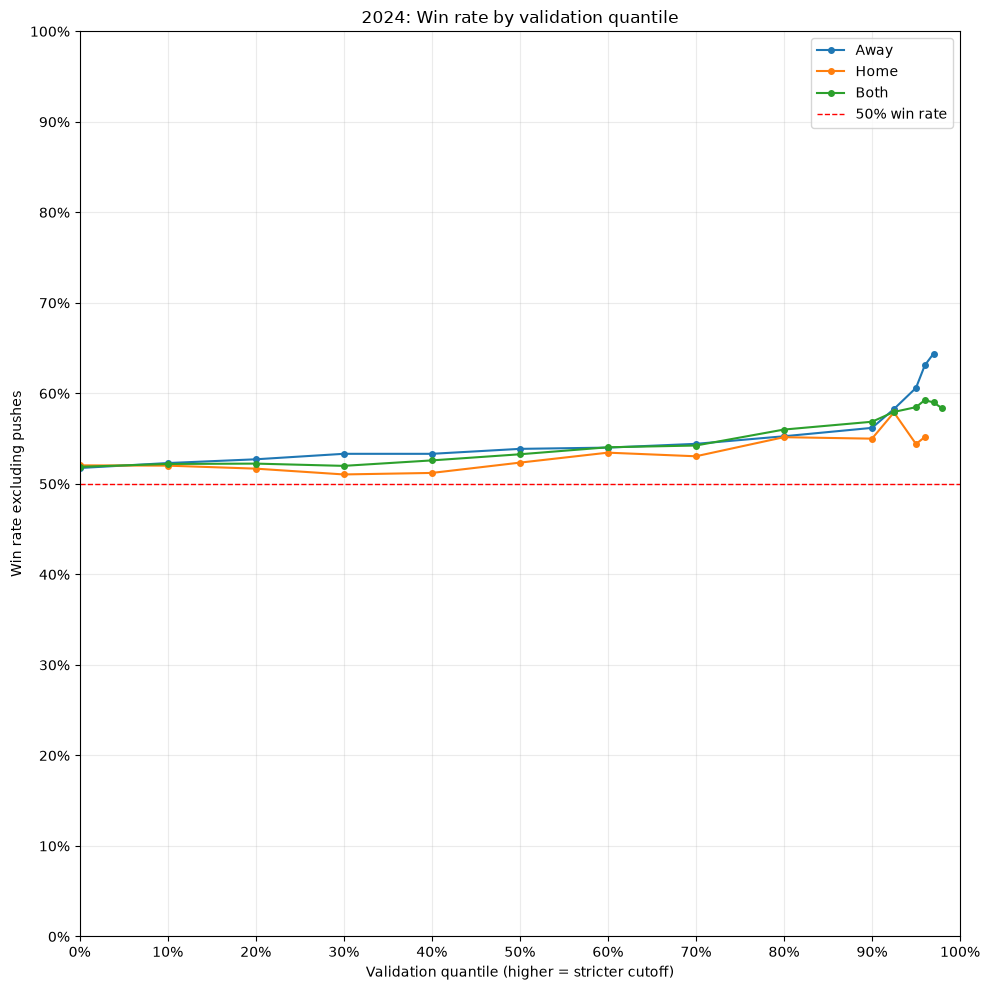

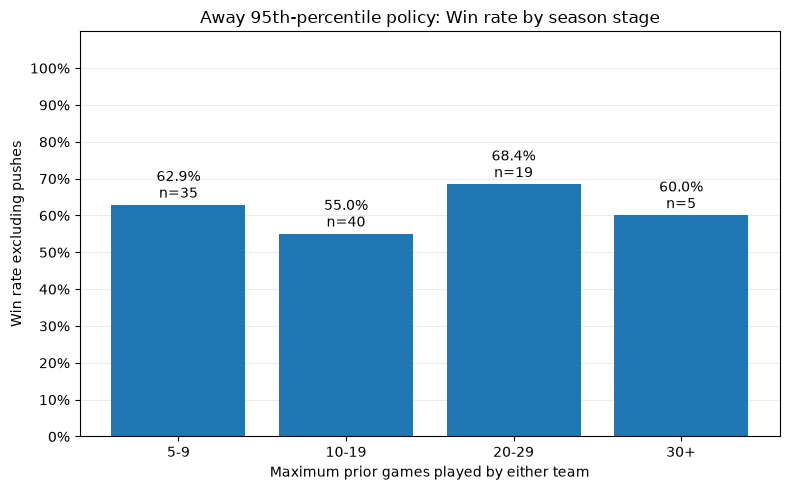

In [18]:
display_experiment_results(dict_2024)

Training seasons: [2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021]
Validation seasons: [2022, 2023, 2024]
Test season: 2025

Selected features for the final model:
['spread', 'diff_net_rating', 'diff_three_point_field_goal_percentage', 'diff_steal_rate', 'diff_offensive_rebound_percentage_ewm', 'diff_opp_three_point_field_goal_percentage', 'away_pace_ewm', 'diff_assist_rate', 'diff_three_point_attempt_rate_smoothed_ewm', 'diff_block_rate', 'away_pace', 'diff_defensive_rebound_percentage', 'diff_opp_turnover_rate', 'diff_opp_points_in_the_paint_share', 'diff_true_shooting_percentage', 'neutral_site', 'diff_three_point_attempt_rate_ewm', 'diff_three_point_attempt_rate', 'diff_turnover_difference', 'diff_pace_ewm']


,Model MAE,Model RMSE,Overall ATS accuracy,Market baseline MAE
0,8.6039,11.0077,52.35%,8.6266


,side,quantile,cutoff_rule,target_top_pct,actual_selected_pct,bets,win_rate,decisions,wins,losses,pushes
0,away,0.0%,pred_edge <= -0.00,100.0%,100.0%,2373,52.04%,2373,1235,1138,0
1,away,10.0%,pred_edge <= -0.09,90.0%,89.9%,2133,52.37%,2133,1117,1016,0
2,away,20.0%,pred_edge <= -0.17,80.0%,80.5%,1911,52.59%,1911,1005,906,0
3,away,30.0%,pred_edge <= -0.26,70.0%,70.9%,1682,53.39%,1682,898,784,0
4,away,40.0%,pred_edge <= -0.35,60.0%,61.9%,1468,53.20%,1468,781,687,0
5,away,50.0%,pred_edge <= -0.45,50.0%,52.5%,1247,53.97%,1247,673,574,0
6,away,60.0%,pred_edge <= -0.55,40.0%,42.6%,1010,55.54%,1010,561,449,0
7,away,70.0%,pred_edge <= -0.68,30.0%,31.9%,758,56.46%,758,428,330,0
8,away,80.0%,pred_edge <= -0.84,20.0%,20.0%,474,58.44%,474,277,197,0
9,away,90.0%,pred_edge <= -1.09,10.0%,9.2%,219,61.19%,219,134,85,0


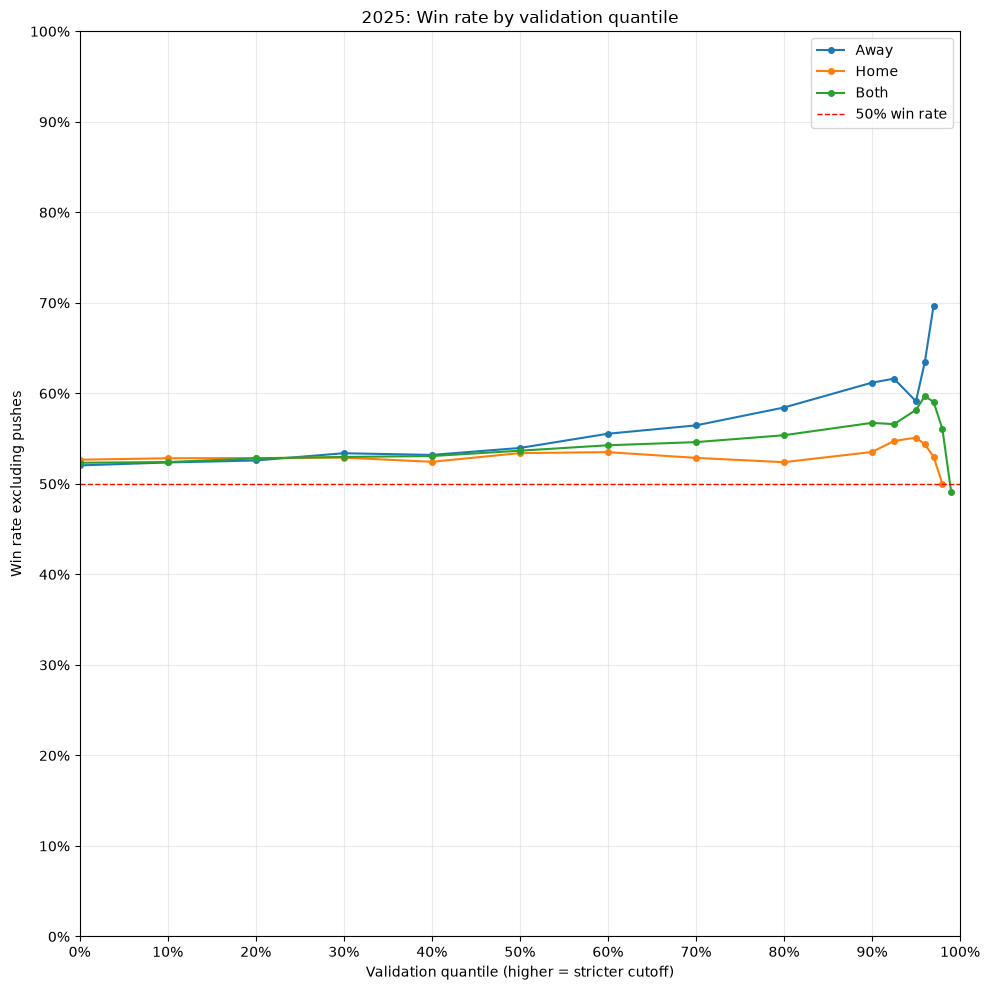

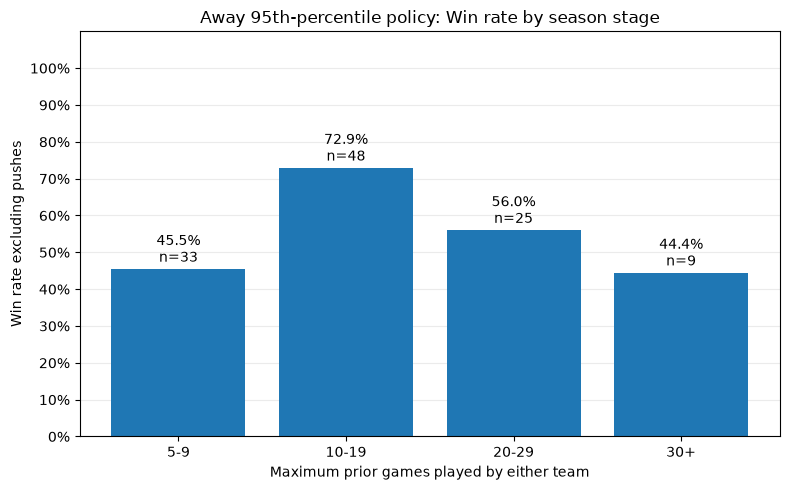

In [19]:
display_experiment_results(dict_2025)

Training seasons: [2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021]
Validation seasons: [2022, 2023, 2024, 2025]
Test season: 2026

Selected features for the final model:
['spread', 'diff_net_rating', 'diff_three_point_field_goal_percentage', 'diff_offensive_rebound_percentage_ewm', 'diff_opp_three_point_field_goal_percentage', 'diff_steal_rate', 'diff_block_rate', 'away_pace_ewm', 'away_pace', 'diff_assist_rate', 'diff_opp_effective_field_goal_percentage_ewm', 'diff_defensive_rebound_percentage', 'diff_three_point_attempt_rate_ewm', 'diff_true_shooting_percentage', 'diff_three_point_attempt_rate_smoothed_ewm', 'diff_opp_points_in_the_paint_share', 'diff_pace', 'diff_offensive_rebound_percentage', 'diff_offensive_rebound_percentage_smoothed_ewm', 'neutral_site']


,Model MAE,Model RMSE,Overall ATS accuracy,Market baseline MAE
0,8.9315,11.2776,50.86%,8.9418


,side,quantile,cutoff_rule,target_top_pct,actual_selected_pct,bets,win_rate,decisions,wins,losses,pushes
0,away,0.0%,pred_edge <= -0.00,100.0%,100.0%,2462,51.54%,2462,1269,1193,0
1,away,10.0%,pred_edge <= -0.08,90.0%,90.0%,2216,52.08%,2216,1154,1062,0
2,away,20.0%,pred_edge <= -0.16,80.0%,80.1%,1971,52.00%,1971,1025,946,0
3,away,30.0%,pred_edge <= -0.24,70.0%,69.5%,1711,52.31%,1711,895,816,0
4,away,40.0%,pred_edge <= -0.32,60.0%,60.9%,1500,52.20%,1500,783,717,0
5,away,50.0%,pred_edge <= -0.41,50.0%,49.8%,1225,51.84%,1225,635,590,0
6,away,60.0%,pred_edge <= -0.52,40.0%,38.4%,945,53.65%,945,507,438,0
7,away,70.0%,pred_edge <= -0.64,30.0%,28.0%,689,54.43%,689,375,314,0
8,away,80.0%,pred_edge <= -0.80,20.0%,17.7%,437,55.61%,437,243,194,0
9,away,90.0%,pred_edge <= -1.04,10.0%,7.5%,185,56.76%,185,105,80,0


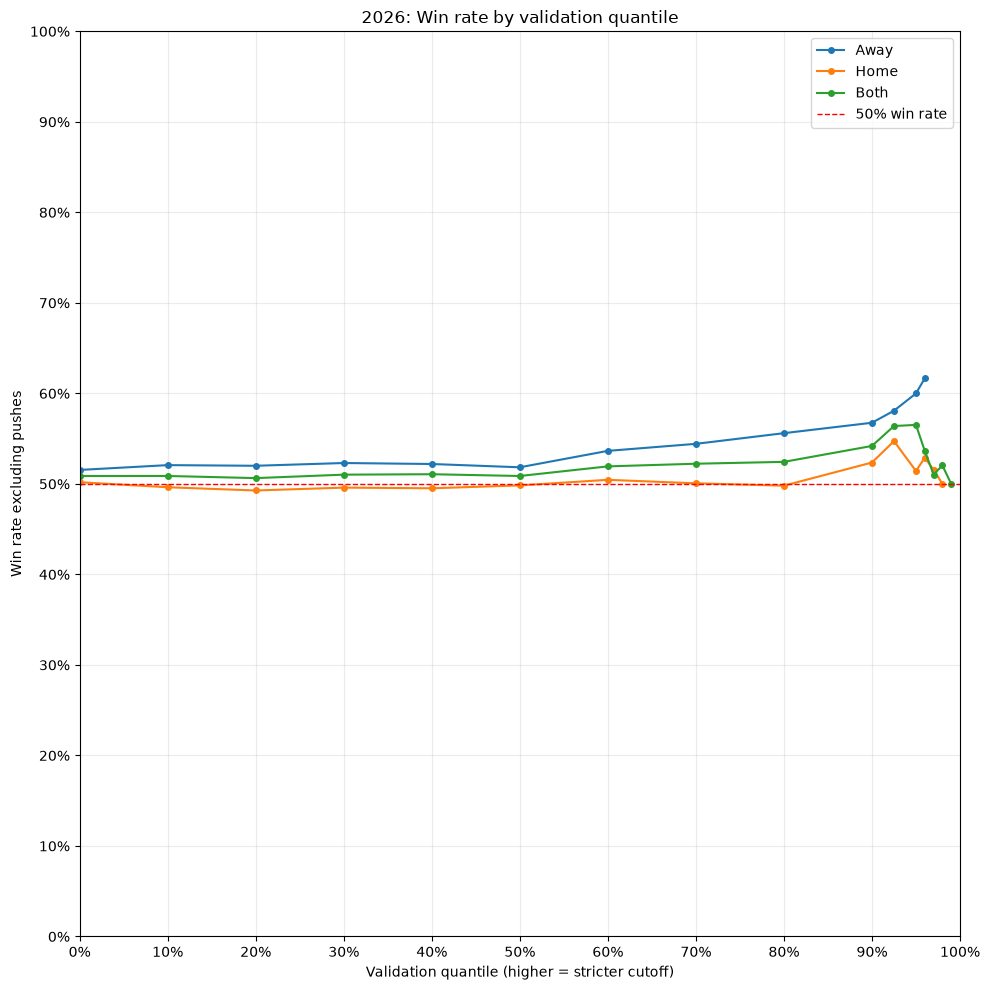

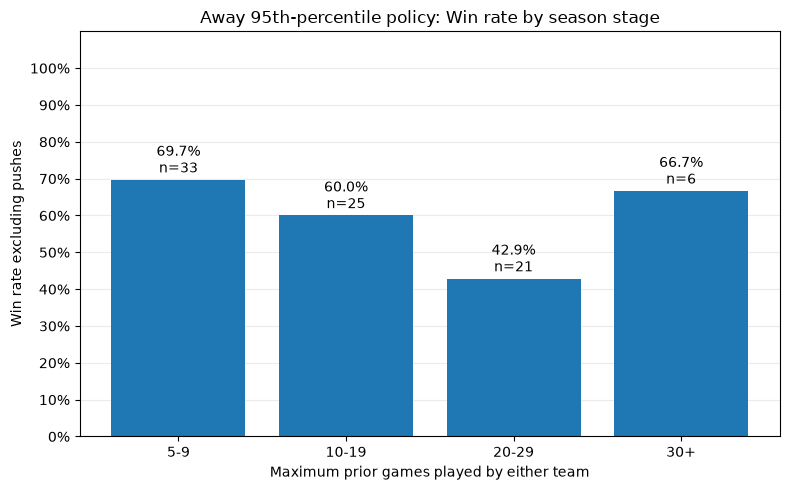

In [20]:
display_experiment_results(dict_2026)

In [21]:
# Method for comparing experiments across different seasons
def display_policy_comparison(*experiments):
    rows = []

    for experiment in experiments:
        cutoffs = experiment["quantile_cutoffs"]

        cutoff = cutoffs.loc[(cutoffs["side"] == "away") & np.isclose(cutoffs["quantile"], 0.95), "cutoff"].iloc[0]

        quantile_results = build_quantile_results_df(experiment["test_predictions"], cutoffs)

        policy = quantile_results.loc[(quantile_results["side"] == "away") & np.isclose(quantile_results["quantile"], 0.95)].iloc[0]

        rows.append({
            "Test season": experiment["test_season"],
            "Away cutoff": -cutoff,
            "Bets": int(policy["bets"]),
            "Wins": int(policy["wins"]),
            "Losses": int(policy["losses"]),
            "Pushes": int(policy["pushes"]),
            "Win rate": policy["win_rate"],
        })

    comparison = (
        pd.DataFrame(rows)
        .sort_values("Test season")
        .reset_index(drop=True)
    )

    display(
        comparison.style
        .set_caption("Away 95th-Percentile Policy: Results Across Seasons")
        .hide(axis="index")
        .format({
            "Away cutoff": "{:.4f}",
            "Win rate": "{:.2%}",
        })
    )

    return comparison

## Selected Policy Across Seasons

The selected policy favors away teams when their predicted edge passes the
away 95th-percentile cutoff. This policy was chosen during development using
the 2024 and 2025 results.

Each season uses its own validation-derived numerical cutoff, while the policy
definition remains unchanged. The comparison table reports selection volume,
wins, losses, pushes, and win rate for each season.

Results at other sides and quantiles are exploratory comparisons. The overall
error metrics provide context for whether the model improves on the market
across all evaluated games, while the selected-policy results describe a
smaller subset.

In [22]:
policy_comparison = display_policy_comparison(
    dict_2024,
    dict_2025,
    dict_2026,
)

Test season,Away cutoff,Bets,Wins,Losses,Pushes,Win rate
2024,-1.3854,99,60,39,0,60.61%
2025,-1.3114,115,68,47,0,59.13%
2026,-1.2408,85,51,34,0,60.00%


In [26]:
# Save 2026 model, feature list, and determined away cutoff for pipeline use/demonstration
joblib.dump(dict_2026["final_model"], "model.joblib")
joblib.dump(dict_2026["selected_features"], "model_features.joblib")

# Extract away cutoff
quantile_cutoffs = dict_2026["quantile_cutoffs"]
cutoff = -quantile_cutoffs.loc[(quantile_cutoffs["side"] == "away") & np.isclose(quantile_cutoffs["quantile"], 0.95), "cutoff"].iloc[0]

joblib.dump(cutoff, "away_cutoff.joblib")



['away_cutoff.joblib']

## Limitations and Next Steps

Strict cutoffs can produce small samples, making observed win rates sensitive
to a few outcomes. Season-stage subsets are smaller still. A high observed
win rate alone does not establish a persistent advantage.

Multiple feature sets, modeling approaches, and thresholds were explored
during development, including experiments involving the 2026 season.
These results are retrospective evaluations rather than evidence from a
completely untouched final holdout.

Historical results also depend on the availability and timing of the source
data and betting lines. Win rates do not directly establish achievable
returns: pricing, line movement, and execution conditions matter.

The next step is to freeze the model-development procedure and selection
policy, then record predictions before games in a future season. This would
provide a clearer prospective evaluation of the complete pipeline.